In [1]:
import pandas as pd

C:\Users\chait\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv(r"C:\Users\chait\ML Uni 2\train_LZdllcl.csv")

In [3]:
df

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54803,3030,Technology,region_14,Bachelor's,m,sourcing,1,48,3.0,17,0,0,78,0
54804,74592,Operations,region_27,Master's & above,f,other,1,37,2.0,6,0,0,56,0
54805,13918,Analytics,region_1,Bachelor's,m,other,1,27,5.0,3,1,0,79,0
54806,13614,Sales & Marketing,region_9,NaN,m,sourcing,1,29,1.0,2,0,0,45,0


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isna().sum()

employee_id                0
department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64

In [6]:
import seaborn as sns

In [7]:
df.drop(columns=['employee_id'],inplace=True)

In [8]:
import matplotlib.pyplot as plt

<Axes: >

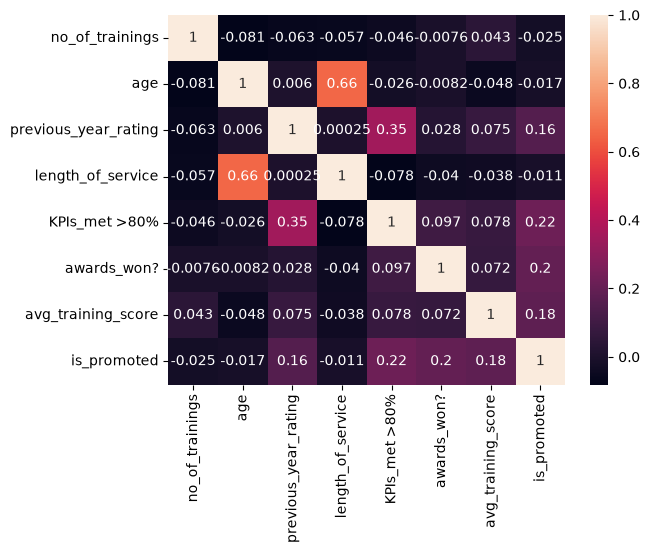

In [9]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [10]:
pd.crosstab(df['department'], df['education'])

education,Bachelor's,Below Secondary,Master's & above
department,,,
Analytics,3978,0,1037
Finance,1895,106,499
HR,1525,128,733
Legal,814,65,156
Operations,7781,176,3165
Procurement,4393,129,2544
R&D,542,0,429
Sales & Marketing,11099,0,4166
Technology,4642,201,2196


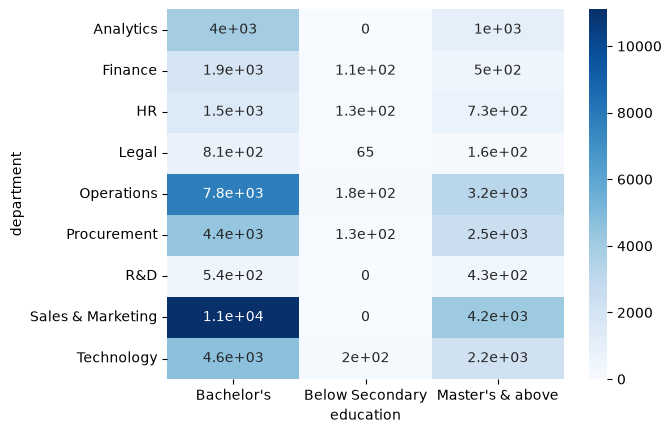

In [11]:


ct = pd.crosstab(df['department'], df['education'])

sns.heatmap(ct, annot=True, cmap='Blues')
plt.show()

In [12]:
df[df['education'].isna()]

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
10,Technology,region_23,NaN,m,sourcing,1,30,NaN,1,0,0,77,0
21,Operations,region_15,NaN,m,sourcing,1,41,4.0,11,0,0,57,0
32,Sales & Marketing,region_7,NaN,f,sourcing,1,24,1.0,2,0,0,48,0
43,Sales & Marketing,region_2,NaN,m,other,3,24,2.0,2,0,0,48,0
82,Sales & Marketing,region_2,NaN,m,sourcing,2,25,3.0,2,0,0,53,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
54692,Sales & Marketing,region_2,NaN,f,sourcing,1,35,3.0,7,0,0,53,0
54717,Analytics,region_2,NaN,m,sourcing,1,32,3.0,4,0,0,86,0
54729,HR,region_2,NaN,f,other,1,28,3.0,2,0,0,53,0
54742,Sales & Marketing,region_31,NaN,m,other,1,28,4.0,3,0,0,47,0


In [13]:
for i in ['region','gender','recruitment_channel']:
    print(pd.crosstab(df[i], df['education']))

education  Bachelor's  Below Secondary  Master's & above
region                                                  
region_1          339                1               256
region_10         251                0               393
region_11        1011                0               280
region_12         468                0                30
region_13        1716                4               872
region_14         637                1               166
region_15        1970                0               647
region_16        1099               37               274
region_17         577                0               210
region_18          31                0                 0
region_19         736                0               128
region_2         7247              482              3768
region_20         619                0               230
region_21         331                1                71
region_22        4308              111              1689
region_23         657          

In [14]:
# Education and numeric missing values are imputed inside the model pipelines after the data split.


In [15]:
df.isna().sum()

department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64

In [16]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline

In [17]:
pip1 = Pipeline([('iter_imp',IterativeImputer())])

In [18]:
df.columns

Index(['department', 'region', 'education', 'gender', 'recruitment_channel',
       'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service',
       'KPIs_met >80%', 'awards_won?', 'avg_training_score', 'is_promoted'],
      dtype='str')

In [19]:
df.select_dtypes(include='number')

,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,1,35,5.0,8,1,0,49,0
1,1,30,5.0,4,0,0,60,0
2,1,34,3.0,7,0,0,50,0
3,2,39,1.0,10,0,0,50,0
4,1,45,3.0,2,0,0,73,0
...,...,...,...,...,...,...,...,...
54803,1,48,3.0,17,0,0,78,0
54804,1,37,2.0,6,0,0,56,0
54805,1,27,5.0,3,1,0,79,0
54806,1,29,1.0,2,0,0,45,0


In [20]:
df.select_dtypes(exclude='number')

,department,region,education,gender,recruitment_channel
0,Sales & Marketing,region_7,Master's & above,f,sourcing
1,Operations,region_22,Bachelor's,m,other
2,Sales & Marketing,region_19,Bachelor's,m,sourcing
3,Sales & Marketing,region_23,Bachelor's,m,other
4,Technology,region_26,Bachelor's,m,other
...,...,...,...,...,...
54803,Technology,region_14,Bachelor's,m,sourcing
54804,Operations,region_27,Master's & above,f,other
54805,Analytics,region_1,Bachelor's,m,other
54806,Sales & Marketing,region_9,NaN,m,sourcing


In [21]:
df['region'].unique()

<ArrowStringArray>
[ 'region_7', 'region_22', 'region_19', 'region_23', 'region_26',  'region_2',
 'region_20', 'region_34',  'region_1',  'region_4', 'region_29', 'region_31',
 'region_15', 'region_14', 'region_11',  'region_5', 'region_28', 'region_17',
 'region_13', 'region_16', 'region_25', 'region_10', 'region_27', 'region_30',
 'region_12', 'region_21',  'region_8', 'region_32',  'region_6', 'region_33',
 'region_24',  'region_3',  'region_9', 'region_18']
Length: 34, dtype: str

In [22]:
df['education'].unique()

<ArrowStringArray>
['Master's & above', 'Bachelor's', nan, 'Below Secondary']
Length: 4, dtype: str

In [23]:
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder

In [24]:
nominal = ['department','region','gender']
ordina = ['education']
it_list = ['previous_year_rating']

In [25]:
education_order = [['Below Secondary',"Bachelor's","Master's & above"]]

In [26]:
pip2 = Pipeline([('nom',OneHotEncoder(drop='first'))])

pip3 = Pipeline([('ord',OrdinalEncoder(categories=education_order))])

In [27]:
from sklearn.compose import ColumnTransformer

In [28]:
pre = ColumnTransformer([('p1',pip1,it_list),
                        ('p2',pip2,nominal),
                        ('p3',pip3,ordina)])

In [29]:
pre

ColumnTransformer(transformers=[('p1',
                                 Pipeline(steps=[('iter_imp',
                                                  IterativeImputer())]),
                                 ['previous_year_rating']),
                                ('p2',
                                 Pipeline(steps=[('nom',
                                                  OneHotEncoder(drop='first'))]),
                                 ['department', 'region', 'gender']),
                                ('p3',
                                 Pipeline(steps=[('ord',
                                                  OrdinalEncoder(categories=[['Below '
                                                                              'Secondary',
                                                                              "Bachelor's",
                                                                              "Master's "
                                                                              '& '
                                                                              'above']]))]),
                                 ['education'])])

# Imbalanced promotion classification: model comparison and F1 tuning

The positive class is rare, so models use class weighting or training-only oversampling where supported. Validation probabilities are used to select each model's F1 threshold. Optuna tuning uses stratified cross-validation. The final comparison reports F1 only.


In [30]:
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import RandomOverSampler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
    AdaBoostClassifier, HistGradientBoostingClassifier,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from catboost import CatBoostClassifier

RANDOM_STATE = 42


In [31]:
# `df` was loaded and explored above. employee_id is an identifier, not a predictive feature.
X = df.drop(columns=['is_promoted', 'employee_id'], errors='ignore').copy()
y = df['is_promoted'].astype('int8').copy()

# Feature engineering: add ratio and interaction columns before splitting the data.
# These same columns are created later for the separate unlabeled test file.
X['training_per_service'] = X['no_of_trainings'] / (X['length_of_service'] + 1)
X['score_x_kpi'] = X['avg_training_score'] * X['KPIs_met >80%']
X['rating_x_kpi'] = X['previous_year_rating'] * X['KPIs_met >80%']
X['age_service_gap'] = X['age'] - X['length_of_service']
categorical = X.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
numeric = [col for col in X.columns if col not in categorical]

# Hold out the final test set first. The remaining data is split into train and validation.
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid, y_train_valid, test_size=0.25,
    stratify=y_train_valid, random_state=RANDOM_STATE + 1,
)
print(f'Train: {len(X_train):,} | Validation: {len(X_valid):,} | Test: {len(X_test):,}')
print(f'Positive promotion rate: train={y_train.mean():.2%}, validation={y_valid.mean():.2%}, test={y_test.mean():.2%}')
print('Training class counts before balancing:')
print(y_train.value_counts().sort_index().rename(index={0: 'Not promoted (0)', 1: 'Promoted (1)'}))

# Balanced sample weights are passed to estimators that support them.
train_sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

# One-hot features suit linear, distance, and bagged tree models.
onehot_preprocessor = ColumnTransformer([
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical),
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler(with_mean=False)),
    ]), numeric),
], sparse_threshold=0.3)
X_train_ohe = onehot_preprocessor.fit_transform(X_train)
X_valid_ohe = onehot_preprocessor.transform(X_valid)
X_test_ohe = onehot_preprocessor.transform(X_test)

# Dense one-hot matrix for GaussianNB.
dense_preprocessor = ColumnTransformer([
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical),
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), numeric),
], sparse_threshold=0)
X_train_dense = dense_preprocessor.fit_transform(X_train)
X_valid_dense = dense_preprocessor.transform(X_valid)
X_test_dense = dense_preprocessor.transform(X_test)

# Ordinal encoded categories for histogram/gradient tree implementations.
ordinal_preprocessor = ColumnTransformer([
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ]), categorical),
    ('numeric', SimpleImputer(strategy='median'), numeric),
], sparse_threshold=0)
X_train_ord = ordinal_preprocessor.fit_transform(X_train)
X_valid_ord = ordinal_preprocessor.transform(X_valid)
X_test_ord = ordinal_preprocessor.transform(X_test)

# CatBoost uses category text directly. Copy each split and fill category nulls.
X_train_cat = X_train.copy()
X_valid_cat = X_valid.copy()
X_test_cat = X_test.copy()
for col in categorical:
    X_train_cat[col] = X_train_cat[col].fillna('__MISSING__').astype(str)
    X_valid_cat[col] = X_valid_cat[col].fillna('__MISSING__').astype(str)
    X_test_cat[col] = X_test_cat[col].fillna('__MISSING__').astype(str)


Train: 32,884 | Validation: 10,962 | Test: 10,962
Positive promotion rate: train=8.51%, validation=8.52%, test=8.52%
Training class counts before balancing:
is_promoted
Not promoted (0)    30084
Promoted (1)         2800
Name: count, dtype: int64


## Fit each algorithm and select its F1 threshold

Class imbalance is addressed with balanced class weights for supported models. KNN uses RandomOverSampler on training features only. Each model's probability threshold is selected using validation F1.


In [32]:
# Fit Logistic Regression with imbalance handling, then select a threshold using validation F1.
lr_model = LogisticRegression(C=1.0,max_iter=1500,n_jobs=4,class_weight='balanced')
lr_model.fit(X_train_ohe,y_train)

lr_model_valid_scores = lr_model.predict_proba(X_valid_ohe)[:, 1]
lr_model_thresholds = np.unique(np.quantile(lr_model_valid_scores, np.linspace(0, 1, 201)))
lr_model_threshold = lr_model_thresholds[0]
lr_model_best_f1 = 0.0
for cutoff in lr_model_thresholds:
    lr_model_valid_predictions = (lr_model_valid_scores >= cutoff).astype('int8')
    lr_model_current_f1 = f1_score(y_valid, lr_model_valid_predictions, zero_division=0)
    if lr_model_current_f1 > lr_model_best_f1:
        lr_model_best_f1 = lr_model_current_f1
        lr_model_threshold = cutoff

lr_model_test_scores = lr_model.predict_proba(X_test_ohe)[:, 1]
lr_model_test_predictions = (lr_model_test_scores >= lr_model_threshold).astype('int8')
lr_model_test_f1 = f1_score(y_test, lr_model_test_predictions, zero_division=0)
print('Logistic Regression validation F1:', round(lr_model_best_f1, 4), '| selected cutoff:', round(lr_model_threshold, 4))


Logistic Regression validation F1: 0.4054 | selected cutoff: 0.829


In [33]:
# Fit KNN Classifier with imbalance handling, then select a threshold using validation F1.
knn_model = KNeighborsClassifier(n_neighbors=25,weights='distance',n_jobs=4)
knn_sampler = RandomOverSampler(random_state=RANDOM_STATE)
X_train_knn, y_train_knn = knn_sampler.fit_resample(X_train_ohe,y_train)
knn_model.fit(X_train_knn,y_train_knn)

knn_model_valid_scores = knn_model.predict_proba(X_valid_ohe)[:, 1]
knn_model_thresholds = np.unique(np.quantile(knn_model_valid_scores, np.linspace(0, 1, 201)))
knn_model_threshold = knn_model_thresholds[0]
knn_model_best_f1 = 0.0
for cutoff in knn_model_thresholds:
    knn_model_valid_predictions = (knn_model_valid_scores >= cutoff).astype('int8')
    knn_model_current_f1 = f1_score(y_valid, knn_model_valid_predictions, zero_division=0)
    if knn_model_current_f1 > knn_model_best_f1:
        knn_model_best_f1 = knn_model_current_f1
        knn_model_threshold = cutoff

knn_model_test_scores = knn_model.predict_proba(X_test_ohe)[:, 1]
knn_model_test_predictions = (knn_model_test_scores >= knn_model_threshold).astype('int8')
knn_model_test_f1 = f1_score(y_test, knn_model_test_predictions, zero_division=0)
print('KNN Classifier validation F1:', round(knn_model_best_f1, 4), '| selected cutoff:', round(knn_model_threshold, 4))


KNN Classifier validation F1: 0.3455 | selected cutoff: 0.598


In [34]:
# Fit SVC with imbalance handling, then select a threshold using validation F1.
svc_model = SVC(C=1.0,kernel='rbf',cache_size=512,class_weight='balanced',probability=True,random_state=RANDOM_STATE)
svc_model.fit(X_train_ohe,y_train)

svc_model_valid_scores = svc_model.predict_proba(X_valid_ohe)[:, 1]
svc_model_thresholds = np.unique(np.quantile(svc_model_valid_scores, np.linspace(0, 1, 201)))
svc_model_threshold = svc_model_thresholds[0]
svc_model_best_f1 = 0.0
for cutoff in svc_model_thresholds:
    svc_model_valid_predictions = (svc_model_valid_scores >= cutoff).astype('int8')
    svc_model_current_f1 = f1_score(y_valid, svc_model_valid_predictions, zero_division=0)
    if svc_model_current_f1 > svc_model_best_f1:
        svc_model_best_f1 = svc_model_current_f1
        svc_model_threshold = cutoff

svc_model_test_scores = svc_model.predict_proba(X_test_ohe)[:, 1]
svc_model_test_predictions = (svc_model_test_scores >= svc_model_threshold).astype('int8')
svc_model_test_f1 = f1_score(y_test, svc_model_test_predictions, zero_division=0)
print('SVC validation F1:', round(svc_model_best_f1, 4), '| selected cutoff:', round(svc_model_threshold, 4))


SVC validation F1: 0.3621 | selected cutoff: 0.134


In [35]:
# Fit Naive Bayes with imbalance handling, then select a threshold using validation F1.
nb_model = GaussianNB()
nb_model.fit(X_train_dense,y_train,sample_weight=train_sample_weights)

nb_model_valid_scores = nb_model.predict_proba(X_valid_dense)[:, 1]
nb_model_thresholds = np.unique(np.quantile(nb_model_valid_scores, np.linspace(0, 1, 201)))
nb_model_threshold = nb_model_thresholds[0]
nb_model_best_f1 = 0.0
for cutoff in nb_model_thresholds:
    nb_model_valid_predictions = (nb_model_valid_scores >= cutoff).astype('int8')
    nb_model_current_f1 = f1_score(y_valid, nb_model_valid_predictions, zero_division=0)
    if nb_model_current_f1 > nb_model_best_f1:
        nb_model_best_f1 = nb_model_current_f1
        nb_model_threshold = cutoff

nb_model_test_scores = nb_model.predict_proba(X_test_dense)[:, 1]
nb_model_test_predictions = (nb_model_test_scores >= nb_model_threshold).astype('int8')
nb_model_test_f1 = f1_score(y_test, nb_model_test_predictions, zero_division=0)
print('Naive Bayes validation F1:', round(nb_model_best_f1, 4), '| selected cutoff:', round(nb_model_threshold, 4))


Naive Bayes validation F1: 0.2715 | selected cutoff: 0.9723


In [36]:
# Fit Decision Tree with imbalance handling, then select a threshold using validation F1.
dt_model = DecisionTreeClassifier(max_depth=10,min_samples_leaf=20,class_weight='balanced',random_state=RANDOM_STATE)
dt_model.fit(X_train_ord,y_train)

dt_model_valid_scores = dt_model.predict_proba(X_valid_ord)[:, 1]
dt_model_thresholds = np.unique(np.quantile(dt_model_valid_scores, np.linspace(0, 1, 201)))
dt_model_threshold = dt_model_thresholds[0]
dt_model_best_f1 = 0.0
for cutoff in dt_model_thresholds:
    dt_model_valid_predictions = (dt_model_valid_scores >= cutoff).astype('int8')
    dt_model_current_f1 = f1_score(y_valid, dt_model_valid_predictions, zero_division=0)
    if dt_model_current_f1 > dt_model_best_f1:
        dt_model_best_f1 = dt_model_current_f1
        dt_model_threshold = cutoff

dt_model_test_scores = dt_model.predict_proba(X_test_ord)[:, 1]
dt_model_test_predictions = (dt_model_test_scores >= dt_model_threshold).astype('int8')
dt_model_test_f1 = f1_score(y_test, dt_model_test_predictions, zero_division=0)
print('Decision Tree validation F1:', round(dt_model_best_f1, 4), '| selected cutoff:', round(dt_model_threshold, 4))


Decision Tree validation F1: 0.4419 | selected cutoff: 0.8392


In [37]:
# Fit Random Forest with imbalance handling, then select a threshold using validation F1.
rf_model = RandomForestClassifier(n_estimators=250,min_samples_leaf=2,max_features='sqrt',n_jobs=4,class_weight='balanced_subsample',random_state=RANDOM_STATE)
rf_model.fit(X_train_ohe,y_train)

rf_model_valid_scores = rf_model.predict_proba(X_valid_ohe)[:, 1]
rf_model_thresholds = np.unique(np.quantile(rf_model_valid_scores, np.linspace(0, 1, 201)))
rf_model_threshold = rf_model_thresholds[0]
rf_model_best_f1 = 0.0
for cutoff in rf_model_thresholds:
    rf_model_valid_predictions = (rf_model_valid_scores >= cutoff).astype('int8')
    rf_model_current_f1 = f1_score(y_valid, rf_model_valid_predictions, zero_division=0)
    if rf_model_current_f1 > rf_model_best_f1:
        rf_model_best_f1 = rf_model_current_f1
        rf_model_threshold = cutoff

rf_model_test_scores = rf_model.predict_proba(X_test_ohe)[:, 1]
rf_model_test_predictions = (rf_model_test_scores >= rf_model_threshold).astype('int8')
rf_model_test_f1 = f1_score(y_test, rf_model_test_predictions, zero_division=0)
print('Random Forest validation F1:', round(rf_model_best_f1, 4), '| selected cutoff:', round(rf_model_threshold, 4))


Random Forest validation F1: 0.4777 | selected cutoff: 0.4229


In [38]:
# Fit ExtraTrees with imbalance handling, then select a threshold using validation F1.
et_model = ExtraTreesClassifier(n_estimators=250,min_samples_leaf=2,max_features='sqrt',n_jobs=4,class_weight='balanced',random_state=RANDOM_STATE)
et_model.fit(X_train_ohe,y_train)

et_model_valid_scores = et_model.predict_proba(X_valid_ohe)[:, 1]
et_model_thresholds = np.unique(np.quantile(et_model_valid_scores, np.linspace(0, 1, 201)))
et_model_threshold = et_model_thresholds[0]
et_model_best_f1 = 0.0
for cutoff in et_model_thresholds:
    et_model_valid_predictions = (et_model_valid_scores >= cutoff).astype('int8')
    et_model_current_f1 = f1_score(y_valid, et_model_valid_predictions, zero_division=0)
    if et_model_current_f1 > et_model_best_f1:
        et_model_best_f1 = et_model_current_f1
        et_model_threshold = cutoff

et_model_test_scores = et_model.predict_proba(X_test_ohe)[:, 1]
et_model_test_predictions = (et_model_test_scores >= et_model_threshold).astype('int8')
et_model_test_f1 = f1_score(y_test, et_model_test_predictions, zero_division=0)
print('ExtraTrees validation F1:', round(et_model_best_f1, 4), '| selected cutoff:', round(et_model_threshold, 4))


ExtraTrees validation F1: 0.4328 | selected cutoff: 0.5251


In [39]:
# Fit Gradient Boosting with imbalance handling, then select a threshold using validation F1.
gb_model = GradientBoostingClassifier(n_estimators=180,learning_rate=0.06,max_depth=2,min_samples_leaf=20,subsample=0.85,random_state=RANDOM_STATE)
gb_model.fit(X_train_ord,y_train,sample_weight=train_sample_weights)

gb_model_valid_scores = gb_model.predict_proba(X_valid_ord)[:, 1]
gb_model_thresholds = np.unique(np.quantile(gb_model_valid_scores, np.linspace(0, 1, 201)))
gb_model_threshold = gb_model_thresholds[0]
gb_model_best_f1 = 0.0
for cutoff in gb_model_thresholds:
    gb_model_valid_predictions = (gb_model_valid_scores >= cutoff).astype('int8')
    gb_model_current_f1 = f1_score(y_valid, gb_model_valid_predictions, zero_division=0)
    if gb_model_current_f1 > gb_model_best_f1:
        gb_model_best_f1 = gb_model_current_f1
        gb_model_threshold = cutoff

gb_model_test_scores = gb_model.predict_proba(X_test_ord)[:, 1]
gb_model_test_predictions = (gb_model_test_scores >= gb_model_threshold).astype('int8')
gb_model_test_f1 = f1_score(y_test, gb_model_test_predictions, zero_division=0)
print('Gradient Boosting validation F1:', round(gb_model_best_f1, 4), '| selected cutoff:', round(gb_model_threshold, 4))


Gradient Boosting validation F1: 0.3762 | selected cutoff: 0.5948


In [40]:
# Fit AdaBoost with imbalance handling, then select a threshold using validation F1.
ada_model = AdaBoostClassifier(n_estimators=250,learning_rate=0.05,random_state=RANDOM_STATE)
ada_model.fit(X_train_ord,y_train,sample_weight=train_sample_weights)

ada_model_valid_scores = ada_model.predict_proba(X_valid_ord)[:, 1]
ada_model_thresholds = np.unique(np.quantile(ada_model_valid_scores, np.linspace(0, 1, 201)))
ada_model_threshold = ada_model_thresholds[0]
ada_model_best_f1 = 0.0
for cutoff in ada_model_thresholds:
    ada_model_valid_predictions = (ada_model_valid_scores >= cutoff).astype('int8')
    ada_model_current_f1 = f1_score(y_valid, ada_model_valid_predictions, zero_division=0)
    if ada_model_current_f1 > ada_model_best_f1:
        ada_model_best_f1 = ada_model_current_f1
        ada_model_threshold = cutoff

ada_model_test_scores = ada_model.predict_proba(X_test_ord)[:, 1]
ada_model_test_predictions = (ada_model_test_scores >= ada_model_threshold).astype('int8')
ada_model_test_f1 = f1_score(y_test, ada_model_test_predictions, zero_division=0)
print('AdaBoost validation F1:', round(ada_model_best_f1, 4), '| selected cutoff:', round(ada_model_threshold, 4))


AdaBoost validation F1: 0.312 | selected cutoff: 0.3951


In [41]:
# Fit HistGradientBoosting with imbalance handling, then select a threshold using validation F1.
hgb_model = HistGradientBoostingClassifier(max_iter=400,learning_rate=0.07,max_leaf_nodes=25,l2_regularization=3,early_stopping=True,class_weight='balanced',random_state=RANDOM_STATE)
hgb_model.fit(X_train_ord,y_train)

hgb_model_valid_scores = hgb_model.predict_proba(X_valid_ord)[:, 1]
hgb_model_thresholds = np.unique(np.quantile(hgb_model_valid_scores, np.linspace(0, 1, 201)))
hgb_model_threshold = hgb_model_thresholds[0]
hgb_model_best_f1 = 0.0
for cutoff in hgb_model_thresholds:
    hgb_model_valid_predictions = (hgb_model_valid_scores >= cutoff).astype('int8')
    hgb_model_current_f1 = f1_score(y_valid, hgb_model_valid_predictions, zero_division=0)
    if hgb_model_current_f1 > hgb_model_best_f1:
        hgb_model_best_f1 = hgb_model_current_f1
        hgb_model_threshold = cutoff

hgb_model_test_scores = hgb_model.predict_proba(X_test_ord)[:, 1]
hgb_model_test_predictions = (hgb_model_test_scores >= hgb_model_threshold).astype('int8')
hgb_model_test_f1 = f1_score(y_test, hgb_model_test_predictions, zero_division=0)
print('HistGradientBoosting validation F1:', round(hgb_model_best_f1, 4), '| selected cutoff:', round(hgb_model_threshold, 4))


HistGradientBoosting validation F1: 0.4922 | selected cutoff: 0.7625


In [42]:
# Fit XGBoost with imbalance handling, then select a threshold using validation F1.
xgb_model = XGBClassifier(n_estimators=1200,max_depth=4,learning_rate=0.04,min_child_weight=5,subsample=0.85,colsample_bytree=0.9,reg_lambda=4,scale_pos_weight=float((y_train == 0).sum() / (y_train == 1).sum()),objective='binary:logistic',eval_metric='logloss',early_stopping_rounds=100,n_jobs=4,tree_method='hist',random_state=RANDOM_STATE)
xgb_model.fit(X_train_ohe,y_train,eval_set=[(X_valid_ohe,y_valid)],verbose=False)

xgb_model_valid_scores = xgb_model.predict_proba(X_valid_ohe)[:, 1]
xgb_model_thresholds = np.unique(np.quantile(xgb_model_valid_scores, np.linspace(0, 1, 201)))
xgb_model_threshold = xgb_model_thresholds[0]
xgb_model_best_f1 = 0.0
for cutoff in xgb_model_thresholds:
    xgb_model_valid_predictions = (xgb_model_valid_scores >= cutoff).astype('int8')
    xgb_model_current_f1 = f1_score(y_valid, xgb_model_valid_predictions, zero_division=0)
    if xgb_model_current_f1 > xgb_model_best_f1:
        xgb_model_best_f1 = xgb_model_current_f1
        xgb_model_threshold = cutoff

xgb_model_test_scores = xgb_model.predict_proba(X_test_ohe)[:, 1]
xgb_model_test_predictions = (xgb_model_test_scores >= xgb_model_threshold).astype('int8')
xgb_model_test_f1 = f1_score(y_test, xgb_model_test_predictions, zero_division=0)
print('XGBoost validation F1:', round(xgb_model_best_f1, 4), '| selected cutoff:', round(xgb_model_threshold, 4))


XGBoost validation F1: 0.4935 | selected cutoff: 0.7634


In [43]:
# Fit LightGBM with imbalance handling, then select a threshold using validation F1.
lgbm_model = LGBMClassifier(n_estimators=1600,num_leaves=31,learning_rate=0.04,min_child_samples=35,subsample=0.85,colsample_bytree=0.9,reg_lambda=3,class_weight='balanced',n_jobs=4,verbosity=-1,random_state=RANDOM_STATE)
lgbm_model.fit(X_train_ord,y_train,eval_set=[(X_valid_ord,y_valid)],callbacks=[early_stopping(100,verbose=False),log_evaluation(0)])

lgbm_model_valid_scores = lgbm_model.predict_proba(X_valid_ord)[:, 1]
lgbm_model_thresholds = np.unique(np.quantile(lgbm_model_valid_scores, np.linspace(0, 1, 201)))
lgbm_model_threshold = lgbm_model_thresholds[0]
lgbm_model_best_f1 = 0.0
for cutoff in lgbm_model_thresholds:
    lgbm_model_valid_predictions = (lgbm_model_valid_scores >= cutoff).astype('int8')
    lgbm_model_current_f1 = f1_score(y_valid, lgbm_model_valid_predictions, zero_division=0)
    if lgbm_model_current_f1 > lgbm_model_best_f1:
        lgbm_model_best_f1 = lgbm_model_current_f1
        lgbm_model_threshold = cutoff

lgbm_model_test_scores = lgbm_model.predict_proba(X_test_ord)[:, 1]
lgbm_model_test_predictions = (lgbm_model_test_scores >= lgbm_model_threshold).astype('int8')
lgbm_model_test_f1 = f1_score(y_test, lgbm_model_test_predictions, zero_division=0)
print('LightGBM validation F1:', round(lgbm_model_best_f1, 4), '| selected cutoff:', round(lgbm_model_threshold, 4))


C:\Users\chait\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM validation F1: 0.4958 | selected cutoff: 0.7622


In [44]:
# Fit CatBoost with imbalance handling, then select a threshold using validation F1.
cat_model = CatBoostClassifier(iterations=1600,depth=6,learning_rate=0.05,l2_leaf_reg=5,loss_function='Logloss',eval_metric='AUC',auto_class_weights='Balanced',early_stopping_rounds=120,verbose=False,allow_writing_files=False,thread_count=4,random_seed=RANDOM_STATE)
cat_model.fit(X_train_cat,y_train,cat_features=categorical,eval_set=(X_valid_cat,y_valid),verbose=False)

cat_model_valid_scores = cat_model.predict_proba(X_valid_cat)[:, 1]
cat_model_thresholds = np.unique(np.quantile(cat_model_valid_scores, np.linspace(0, 1, 201)))
cat_model_threshold = cat_model_thresholds[0]
cat_model_best_f1 = 0.0
for cutoff in cat_model_thresholds:
    cat_model_valid_predictions = (cat_model_valid_scores >= cutoff).astype('int8')
    cat_model_current_f1 = f1_score(y_valid, cat_model_valid_predictions, zero_division=0)
    if cat_model_current_f1 > cat_model_best_f1:
        cat_model_best_f1 = cat_model_current_f1
        cat_model_threshold = cutoff

cat_model_test_scores = cat_model.predict_proba(X_test_cat)[:, 1]
cat_model_test_predictions = (cat_model_test_scores >= cat_model_threshold).astype('int8')
cat_model_test_f1 = f1_score(y_test, cat_model_test_predictions, zero_division=0)
print('CatBoost validation F1:', round(cat_model_best_f1, 4), '| selected cutoff:', round(cat_model_threshold, 4))


CatBoost validation F1: 0.5114 | selected cutoff: 0.7604


In [45]:
# Compare validation F1 values to identify the leading baseline algorithm.
model_names = ['Logistic Regression','KNN Classifier','SVC','Naive Bayes','Decision Tree','Random Forest','ExtraTrees','Gradient Boosting','AdaBoost','HistGradientBoosting','XGBoost','LightGBM','CatBoost']
validation_f1_scores = [lr_model_best_f1,knn_model_best_f1,svc_model_best_f1,nb_model_best_f1,dt_model_best_f1,rf_model_best_f1,et_model_best_f1,gb_model_best_f1,ada_model_best_f1,hgb_model_best_f1,xgb_model_best_f1,lgbm_model_best_f1,cat_model_best_f1]
best_model_position = int(np.argmax(validation_f1_scores))
best_model_name = model_names[best_model_position]
print('Leading model on validation:',best_model_name)
print('Validation F1:',round(validation_f1_scores[best_model_position],4))


Leading model on validation: CatBoost
Validation F1: 0.5114


## Optuna tuning with 5-fold stratified cross-validation

Each Optuna trial is evaluated with the same 5 stratified folds on the 80% labeled development data. The trial threshold is selected from out-of-fold probabilities. Optuna searches CatBoost depth, learning rate, L2, random strength, and class weighting. The final table reports algorithm F1 scores only. The separate labeled 20% test split is not used to tune trials.


In [46]:
# Use the same stratified folds for every Optuna parameter trial.
from sklearn.model_selection import StratifiedKFold

X_train_valid_cat = X_train_valid.copy()
for col in categorical:
    X_train_valid_cat[col] = X_train_valid_cat[col].fillna('__MISSING__').astype(str)

stratified_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train_valid_cat, y_train_valid))
print('Optuna uses 5-fold StratifiedKFold on', len(X_train_valid_cat), 'labeled development rows.')

# This objective trains one CatBoost model per fold and scores out-of-fold probabilities.
def catboost_cv_objective(trial):
    trial_depth = trial.suggest_int('depth', 5, 8)
    trial_learning_rate = trial.suggest_float('learning_rate', 0.025, 0.10, log=True)
    trial_l2 = trial.suggest_float('l2_leaf_reg', 1.0, 15.0, log=True)
    trial_random_strength = trial.suggest_float('random_strength', 0.0, 3.0)
    trial_weight_choice = trial.suggest_categorical('class_weighting', ['None', 'Balanced', 'SqrtBalanced'])
    trial_weight = None if trial_weight_choice == 'None' else trial_weight_choice

    oof_probabilities = np.zeros(len(X_train_valid_cat), dtype=float)
    fold_tree_counts = []
    for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(stratified_folds, start=1):
        fold_model = CatBoostClassifier(
            iterations=700,
            depth=trial_depth,
            learning_rate=trial_learning_rate,
            l2_leaf_reg=trial_l2,
            random_strength=trial_random_strength,
            loss_function='Logloss',
            eval_metric='AUC',
            auto_class_weights=trial_weight,
            early_stopping_rounds=60,
            verbose=False,
            allow_writing_files=False,
            thread_count=4,
            random_seed=RANDOM_STATE + fold_number,
        )
        fold_model.fit(
            X_train_valid_cat.iloc[fold_train_idx], y_train_valid.iloc[fold_train_idx],
            cat_features=categorical,
            eval_set=(X_train_valid_cat.iloc[fold_valid_idx], y_train_valid.iloc[fold_valid_idx]),
            verbose=False,
        )
        oof_probabilities[fold_valid_idx] = fold_model.predict_proba(X_train_valid_cat.iloc[fold_valid_idx])[:, 1]
        fold_tree_counts.append(int(fold_model.tree_count_))

    # Search a fixed grid of candidate probability cutoffs on the OOF predictions.
    candidate_cutoffs = np.unique(np.quantile(oof_probabilities, np.linspace(0, 1, 201)))
    trial_best_f1 = 0.0
    trial_best_threshold = float(candidate_cutoffs[0])
    for cutoff in candidate_cutoffs:
        oof_predictions = (oof_probabilities >= cutoff).astype('int8')
        current_f1 = f1_score(y_train_valid, oof_predictions, zero_division=0)
        if current_f1 > trial_best_f1:
            trial_best_f1 = current_f1
            trial_best_threshold = float(cutoff)

    # Save the selected threshold and typical early-stopped tree count for refitting.
    trial.set_user_attr('selected_threshold', trial_best_threshold)
    trial.set_user_attr('tree_count', int(np.median(fold_tree_counts)))
    return trial_best_f1

# Four trials compare multiple parameter and class-weight combinations, each with 5 folds.
optuna_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
optuna_study.optimize(catboost_cv_objective, n_trials=4, show_progress_bar=True)

best_cv_trial = optuna_study.best_trial
best_cv_threshold = best_cv_trial.user_attrs['selected_threshold']
best_cv_tree_count = best_cv_trial.user_attrs['tree_count']
best_cv_weight = None if best_cv_trial.params['class_weighting'] == 'None' else best_cv_trial.params['class_weighting']
print('Best 5-fold OOF F1:', round(best_cv_trial.value, 4))
print('Best class weighting:', best_cv_trial.params['class_weighting'])
print('Best OOF threshold:', round(best_cv_threshold, 4))
print('Refit tree count:', best_cv_tree_count)


[I 2026-11-05 16:46:13,594] A new study created in memory with name: no-name-d2535b51-ed2d-473f-9c57-f1e829b91f90


Optuna uses 5-fold StratifiedKFold on 43846 labeled development rows.


  0%|          | 0/4 [00:00<?, ?it/s]

[I 2026-11-05 16:47:44,946] Trial 0 finished with value: 0.5233236151603499 and parameters: {'depth': 6, 'learning_rate': 0.09339573747495579, 'l2_leaf_reg': 7.259248719561363, 'random_strength': 1.7959754525911098, 'class_weighting': 'None'}. Best is trial 0 with value: 0.5233236151603499.


[I 2026-11-05 16:49:52,136] Trial 1 finished with value: 0.5203384315001627 and parameters: {'depth': 8, 'learning_rate': 0.05752376553312526, 'l2_leaf_reg': 6.803900745073704, 'random_strength': 0.06175348288740734, 'class_weighting': 'None'}. Best is trial 0 with value: 0.5233236151603499.


[I 2026-11-05 16:52:09,165] Trial 2 finished with value: 0.5190367718841523 and parameters: {'depth': 5, 'learning_rate': 0.03223743847396823, 'l2_leaf_reg': 2.2793795237650705, 'random_strength': 1.5742692948967134, 'class_weighting': 'SqrtBalanced'}. Best is trial 0 with value: 0.5233236151603499.


[I 2026-11-05 16:54:27,229] Trial 3 finished with value: 0.5206638464041653 and parameters: {'depth': 5, 'learning_rate': 0.03748250548657649, 'l2_leaf_reg': 2.6969628335735174, 'random_strength': 1.3682099526511078, 'class_weighting': 'None'}. Best is trial 0 with value: 0.5233236151603499.
Best 5-fold OOF F1: 0.5233
Best class weighting: None
Best OOF threshold: 0.3028
Refit tree count: 236


In [47]:
# Fit the best CV-tuned CatBoost on the development split and compare every algorithm by F1.
best_cv_model = CatBoostClassifier(
    iterations=best_cv_tree_count,
    depth=best_cv_trial.params['depth'],
    learning_rate=best_cv_trial.params['learning_rate'],
    l2_leaf_reg=best_cv_trial.params['l2_leaf_reg'],
    random_strength=best_cv_trial.params['random_strength'],
    loss_function='Logloss',
    eval_metric='AUC',
    auto_class_weights=best_cv_weight,
    verbose=False,
    allow_writing_files=False,
    thread_count=4,
    random_seed=RANDOM_STATE,
)
best_cv_model.fit(X_train_valid_cat, y_train_valid, cat_features=categorical, verbose=False)

# Baseline algorithms use thresholds chosen on the original validation split.
comparison_models = [
    ('Logistic Regression', lr_model, X_train_ohe, X_valid_ohe, X_test_ohe, lr_model_threshold),
    ('KNN Classifier', knn_model, X_train_ohe, X_valid_ohe, X_test_ohe, knn_model_threshold),
    ('SVC', svc_model, X_train_ohe, X_valid_ohe, X_test_ohe, svc_model_threshold),
    ('Naive Bayes', nb_model, X_train_dense, X_valid_dense, X_test_dense, nb_model_threshold),
    ('Decision Tree', dt_model, X_train_ord, X_valid_ord, X_test_ord, dt_model_threshold),
    ('Random Forest', rf_model, X_train_ohe, X_valid_ohe, X_test_ohe, rf_model_threshold),
    ('ExtraTrees', et_model, X_train_ohe, X_valid_ohe, X_test_ohe, et_model_threshold),
    ('Gradient Boosting', gb_model, X_train_ord, X_valid_ord, X_test_ord, gb_model_threshold),
    ('AdaBoost', ada_model, X_train_ord, X_valid_ord, X_test_ord, ada_model_threshold),
    ('HistGradientBoosting', hgb_model, X_train_ord, X_valid_ord, X_test_ord, hgb_model_threshold),
    ('XGBoost', xgb_model, X_train_ohe, X_valid_ohe, X_test_ohe, xgb_model_threshold),
    ('LightGBM', lgbm_model, X_train_ord, X_valid_ord, X_test_ord, lgbm_model_threshold),
    ('CatBoost baseline', cat_model, X_train_cat, X_valid_cat, X_test_cat, cat_model_threshold),
]
score_rows = []
for model_name, model, Xtr, Xval, Xte, cutoff in comparison_models:
    train_scores = model.predict_proba(Xtr)[:, 1]
    validation_scores = model.predict_proba(Xval)[:, 1]
    test_scores = model.predict_proba(Xte)[:, 1]
    score_rows.append({
        'Algorithm': model_name,
        'Training F1': f1_score(y_train, (train_scores >= cutoff).astype('int8'), zero_division=0),
        'Validation/CV F1': f1_score(y_valid, (validation_scores >= cutoff).astype('int8'), zero_division=0),
        'Test F1': f1_score(y_test, (test_scores >= cutoff).astype('int8'), zero_division=0),
    })

# The Optuna row uses 5-fold out-of-fold F1 for its validation/CV score.
cv_train_scores = best_cv_model.predict_proba(X_train_valid_cat)[:, 1]
cv_test_scores = best_cv_model.predict_proba(X_test_cat)[:, 1]
score_rows.append({
    'Algorithm': 'CatBoost Optuna (5-fold CV)',
    'Training F1': f1_score(y_train_valid, (cv_train_scores >= best_cv_threshold).astype('int8'), zero_division=0),
    'Validation/CV F1': best_cv_trial.value,
    'Test F1': f1_score(y_test, (cv_test_scores >= best_cv_threshold).astype('int8'), zero_division=0),
})

algorithm_scores_df = pd.DataFrame(score_rows).sort_values('Validation/CV F1', ascending=False).reset_index(drop=True)
display(algorithm_scores_df.round(4))
algorithm_scores_df.to_csv(r'C:\Users\chait\ML Uni 2\algorithm_f1_scores_cv_optuna.csv', index=False)

# Refit the CV-selected model on all labeled data, then classify the separate unlabeled test CSV.
X_all_labeled_cat = X.copy()
for col in categorical:
    X_all_labeled_cat[col] = X_all_labeled_cat[col].fillna('__MISSING__').astype(str)
final_model_all_data = CatBoostClassifier(
    iterations=best_cv_tree_count,
    depth=best_cv_trial.params['depth'],
    learning_rate=best_cv_trial.params['learning_rate'],
    l2_leaf_reg=best_cv_trial.params['l2_leaf_reg'],
    random_strength=best_cv_trial.params['random_strength'],
    loss_function='Logloss',
    eval_metric='AUC',
    auto_class_weights=best_cv_weight,
    verbose=False,
    allow_writing_files=False,
    thread_count=4,
    random_seed=RANDOM_STATE,
)
final_model_all_data.fit(X_all_labeled_cat, y, cat_features=categorical, verbose=False)
external_test_data = pd.read_csv(r'C:\Users\chait\ML Uni 2\test_2umaH9m.csv')
X_external_test = external_test_data.drop(columns=['is_promoted', 'employee_id'], errors='ignore').copy()
X_external_test['training_per_service'] = X_external_test['no_of_trainings'] / (X_external_test['length_of_service'] + 1)
X_external_test['score_x_kpi'] = X_external_test['avg_training_score'] * X_external_test['KPIs_met >80%']
X_external_test['rating_x_kpi'] = X_external_test['previous_year_rating'] * X_external_test['KPIs_met >80%']
X_external_test['age_service_gap'] = X_external_test['age'] - X_external_test['length_of_service']
for col in categorical:
    X_external_test[col] = X_external_test[col].fillna('__MISSING__').astype(str)
external_test_probabilities = final_model_all_data.predict_proba(X_external_test)[:, 1]
external_test_predictions = (external_test_probabilities >= best_cv_threshold).astype('int8')
predictions_output = pd.DataFrame({
    'employee_id': external_test_data['employee_id'],
    'promotion_probability': external_test_probabilities,
    'is_promoted': external_test_predictions,
})
predictions_output.to_csv(r'C:\Users\chait\ML Uni 2\promotion_predictions_full_train_cv_optuna.csv', index=False)
import joblib
joblib.dump(final_model_all_data, r'C:\Users\chait\ML Uni 2\promotion_best_model_cv_optuna.joblib')
print(f"CV-selected threshold: {best_cv_threshold:.4f}")
print(f"External test rows: {len(external_test_data):,}; predicted promoted: {int(external_test_predictions.sum()):,}; predicted not promoted: {int((external_test_predictions == 0).sum()):,}")
print('Saved F1-only algorithm comparison and full-data test predictions/model.')


,Algorithm,Training F1,Validation/CV F1,Test F1
0,CatBoost Optuna (5-fold CV),0.5540,0.5233,0.5241
1,CatBoost baseline,0.5765,0.5114,0.5295
2,LightGBM,0.8646,0.4958,0.4987
3,XGBoost,0.6417,0.4935,0.5069
4,HistGradientBoosting,0.5522,0.4922,0.5141
5,Random Forest,0.8844,0.4777,0.4454
6,Decision Tree,0.4860,0.4419,0.4534
7,ExtraTrees,0.8110,0.4328,0.4094
8,Logistic Regression,0.4253,0.4054,0.4283
9,Gradient Boosting,0.3772,0.3762,0.3662


CV-selected threshold: 0.3028
External test rows: 23,490; predicted promoted: 954; predicted not promoted: 22,536
Saved F1-only algorithm comparison and full-data test predictions/model.
